# Risk Management - Group Work Project 1: Data Collection, Cleaning and Exploratory Analysis of Oil Price Drivers

In [2]:
#Install packages
!pip install yfinance fredapi requests pandas matplotlib


In [3]:
#Imports
import yfinance as yf
import pandas as pd
import numpy as np
from fredapi import Fred
import requests


In [4]:
#Yahoo Finance - Financial Data
tickers = {
    "OIL_PRICE_WTI": "CL=F",
    "SP500_INDEX": "^GSPC",
    "USD_INDEX": "DX-Y.NYB",
    "VIX": "^VIX"
}

financial_data = pd.DataFrame()

for name, ticker in tickers.items():
    data = yf.download(ticker, start="2000-01-01")["Close"]
    financial_data[name] = data

financial_data.head()


/tmp/ipykernel_2047/3330281738.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2000-01-01")["Close"]
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2047/3330281738.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2000-01-01")["Close"]
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2047/3330281738.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2000-01-01")["Close"]
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2047/3330281738.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2000-01-01")["Close"]
[*********************100%***********************]  1 of 1 completed


,OIL_PRICE_WTI,SP500_INDEX,USD_INDEX,VIX
Date,,,,
2000-08-23,32.049999,1505.969971,111.419998,17.379999
2000-08-24,31.629999,1508.310059,111.230003,17.040001
2000-08-25,32.049999,1506.449951,111.349998,16.530001
2000-08-28,32.869999,1514.089966,111.459999,16.540001
2000-08-29,32.720001,1509.839966,112.199997,16.889999


In [5]:
#FRED - Macroeconomic Data
fred = Fred(api_key="YOUR_FRED_API_KEY")

macro_series = {
    "GDP_US": "GDP",
    "IND_PROD_US": "INDPRO",
    "CPI_US": "CPIAUCSL"
}

macro_data = pd.DataFrame()

for name, series in macro_series.items():
    macro_data[name] = fred.get_series(series)

macro_data.index = pd.to_datetime(macro_data.index)
macro_data.head()



,GDP_US,IND_PROD_US,CPI_US
1946-01-01,NaN,11.3903,NaN
1946-04-01,NaN,11.7404,NaN
1946-07-01,NaN,12.4136,NaN
1946-10-01,NaN,13.3560,NaN
1947-01-01,243.164,13.6792,21.48


In [6]:
#EIA — Microeconomic Data
import yfinance as yf
import pandas as pd

micro_tickers = {
    "RIG_COUNT_PROXY": "^IRX",
    "ENERGY_SECTOR_XLE": "XLE",
    "OIL_EXPLORATION_XOP": "XOP",
    "US_OIL_FUND_USO": "USO"
}

micro_data = pd.DataFrame()

for name, ticker in micro_tickers.items():
    data = yf.download(ticker, start="2000-01-01")["Close"]
    micro_data[name] = data

micro_data.head()





/tmp/ipykernel_2047/2014490410.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2000-01-01")["Close"]
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2047/2014490410.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2000-01-01")["Close"]
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2047/2014490410.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2000-01-01")["Close"]
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2047/2014490410.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2000-01-01")["Close"]
[*********************100%***********************]  1 of 1 completed


,RIG_COUNT_PROXY,ENERGY_SECTOR_XLE,OIL_EXPLORATION_XOP,US_OIL_FUND_USO
Date,,,,
2000-01-03,5.27,6.655916,NaN,NaN
2000-01-04,5.27,6.530627,NaN,NaN
2000-01-05,5.27,6.702897,NaN,NaN
2000-01-06,5.24,6.961306,NaN,NaN
2000-01-07,5.22,7.035695,NaN,NaN


In [7]:
#SEDAR
# Placeholder for manually extracted SEDAR variables
sedar_data = pd.DataFrame({
    "date": pd.date_range("2000-01-01", periods=5, freq="YE"),
    "PRODUCTION_COST_CAD": [25, 27, 30, 29, 31]
}).set_index("date")


In [8]:
#data.world
# Placeholder for data.world integration
# Replace with actual dataset once downloaded
dataworld_data = pd.DataFrame({
    "date": pd.date_range("2000-01-01", periods=5, freq="YE"),
    "GLOBAL_OIL_SUPPLY": [82, 84, 85, 87, 90]
}).set_index("date")


In [9]:
#Merge All Data
df = financial_data.join([macro_data, micro_data, sedar_data, dataworld_data], how="outer")
df = df.sort_index()
df.head()



,OIL_PRICE_WTI,SP500_INDEX,USD_INDEX,VIX,GDP_US,IND_PROD_US,CPI_US,RIG_COUNT_PROXY,ENERGY_SECTOR_XLE,OIL_EXPLORATION_XOP,US_OIL_FUND_USO,PRODUCTION_COST_CAD,GLOBAL_OIL_SUPPLY
1946-01-01,NaN,NaN,NaN,NaN,NaN,11.3903,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1946-04-01,NaN,NaN,NaN,NaN,NaN,11.7404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1946-07-01,NaN,NaN,NaN,NaN,NaN,12.4136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1946-10-01,NaN,NaN,NaN,NaN,NaN,13.3560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1947-01-01,NaN,NaN,NaN,NaN,243.164,13.6792,21.48,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
#Save Raw data for cleaning step
df.to_csv("oil_project_raw_data.csv")


In [11]:
#Load the Data

import pandas as pd
import numpy as np

df = pd.read_csv("oil_project_raw_data.csv", parse_dates=[0], index_col=0)
df.index.name = "date" # Name the index for consistency
df = df.sort_index()

In [12]:
#Student A Extreme Outliers

import numpy as np

def winsorize(s, z=4):
    mean, std = s.mean(), s.std()
    upper = mean + z * std
    lower = mean - z * std
    return s.clip(lower, upper)

df_outliers = df.apply(winsorize)


In [13]:
#Student B bad data detection

df_bad = df_outliers.copy()

# Remove duplicate timestamps
df_bad = df_bad[~df_bad.index.duplicated(keep="first")]

# Replace impossible negative values
for col in df_bad.columns:
    if any(keyword in col.upper() for keyword in ["PRICE", "INDEX", "FUND", "OIL", "XLE", "XOP"]):
        df_bad.loc[df_bad[col] < 0, col] = np.nan

# Remove sudden jumps > 5 std of first difference
for col in df_bad.columns:
    diff = df_bad[col].diff()
    threshold = 5 * diff.std()
    df_bad.loc[diff.abs() > threshold, col] = np.nan


In [14]:
#Student C Missing value imputation

df_clean = df_bad.copy()

# Identify columns by type
financial_cols = [c for c in df_clean.columns if c.upper() in [
    "OIL_PRICE_WTI", "SP500_INDEX", "USD_INDEX", "VIX",
    "RIG_COUNT_PROXY", "ENERGY_SECTOR_XLE", "OIL_EXPLORATION_XOP", "US_OIL_FUND_USO"
]]

macro_cols = ["GDP_US", "IND_PROD_US", "CPI_US"]

other_cols = [c for c in df_clean.columns if c not in financial_cols + macro_cols]

# Financial: forward-fill then back-fill
df_clean[financial_cols] = df_clean[financial_cols].ffill().bfill()

# Macro: time-based interpolation
df_clean[macro_cols] = df_clean[macro_cols].interpolate(method="time")

# Others: linear interpolation with limit
df_clean[other_cols] = df_clean[other_cols].interpolate(limit=5).ffill().bfill()


In [15]:
#Final Sterilized Dataset

df_sterilized = df_clean.dropna(how="any")
df_sterilized.to_csv("oil_project_sterilized_data.csv")
df_sterilized.head()


,OIL_PRICE_WTI,SP500_INDEX,USD_INDEX,VIX,GDP_US,IND_PROD_US,CPI_US,RIG_COUNT_PROXY,ENERGY_SECTOR_XLE,OIL_EXPLORATION_XOP,US_OIL_FUND_USO,PRODUCTION_COST_CAD,GLOBAL_OIL_SUPPLY
date,,,,,,,,,,,,,
1947-01-01,32.049999,1505.969971,111.419998,17.379999,243.164,13.6792,21.48,5.27,6.655916,105.000633,544.159973,25.0,82.0
1947-04-01,32.049999,1505.969971,111.419998,17.379999,245.968,13.7330,22.00,5.27,6.655916,105.000633,544.159973,25.0,82.0
1947-07-01,32.049999,1505.969971,111.419998,17.379999,249.585,13.7061,22.23,5.27,6.655916,105.000633,544.159973,25.0,82.0
1947-10-01,32.049999,1505.969971,111.419998,17.379999,259.745,14.0292,22.91,5.27,6.655916,105.000633,544.159973,25.0,82.0
1948-01-01,32.049999,1505.969971,111.419998,17.379999,265.742,14.3524,23.68,5.27,6.655916,105.000633,544.159973,25.0,82.0


In [16]:
df = pd.read_csv("oil_project_sterilized_data.csv", parse_dates=True, index_col=0)
df.index.name = "date"

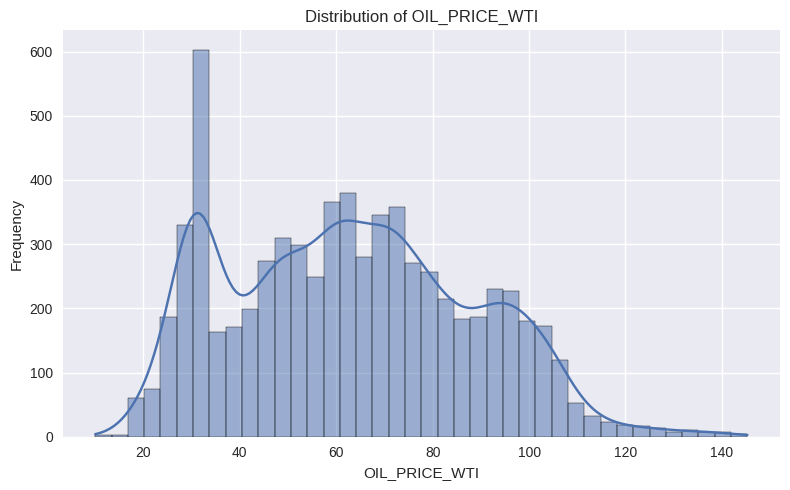

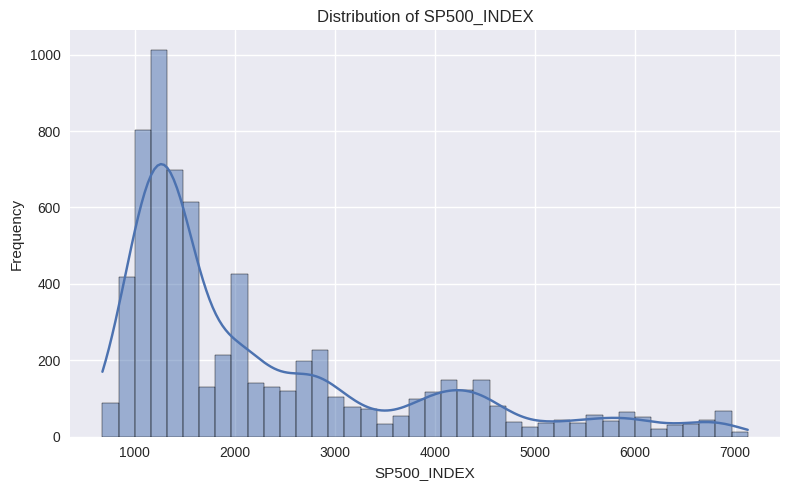

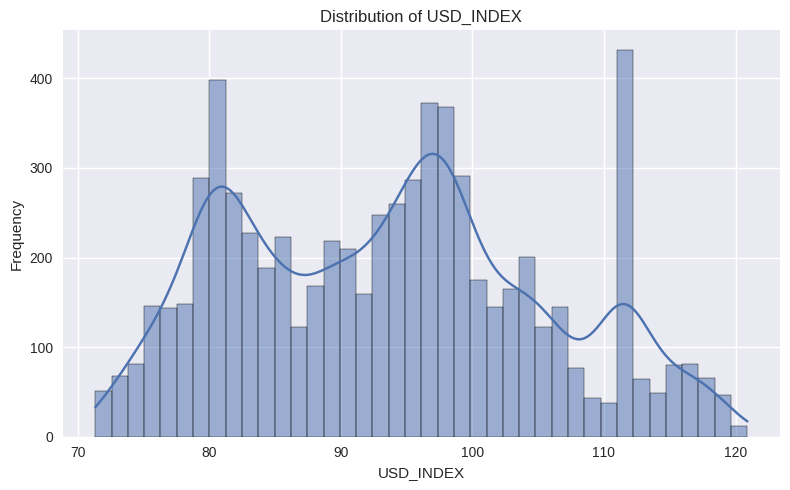

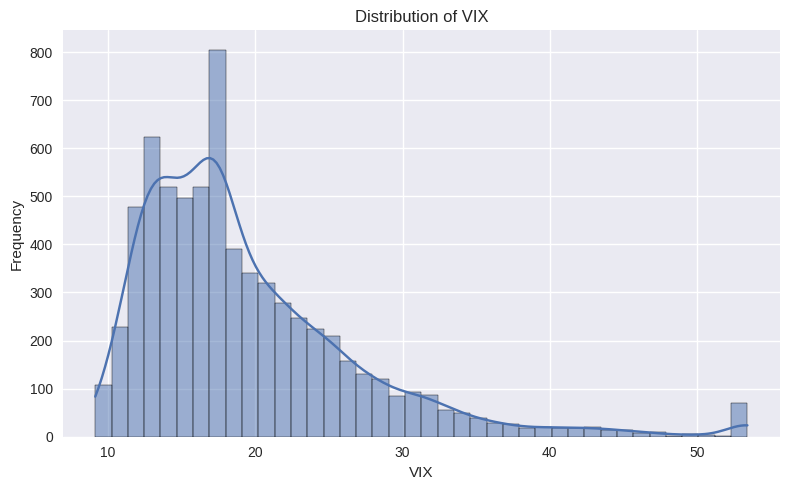

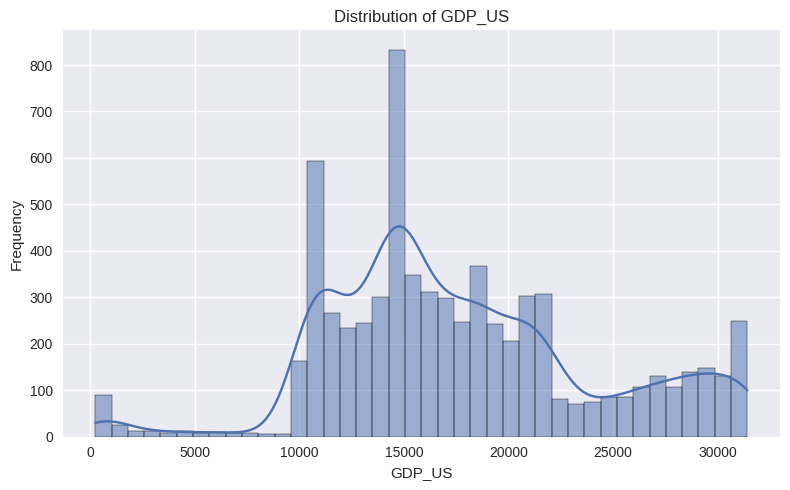

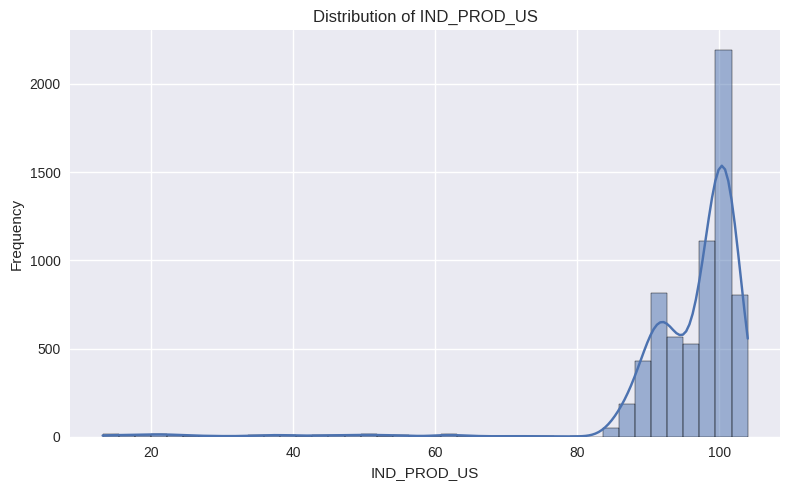

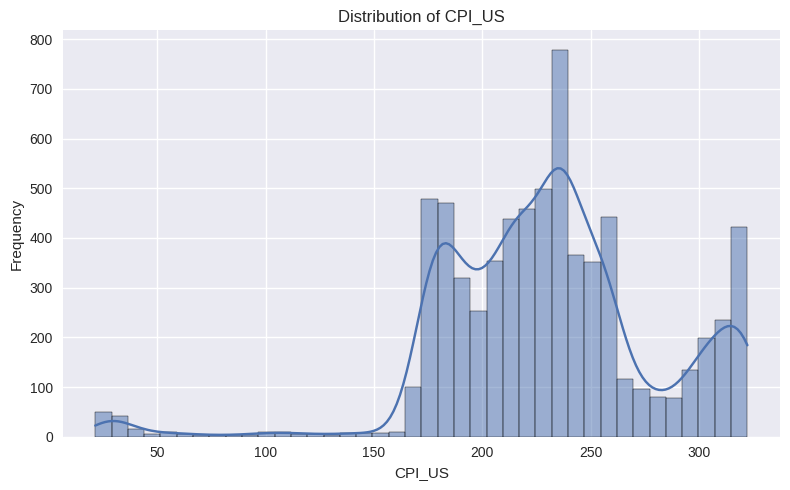

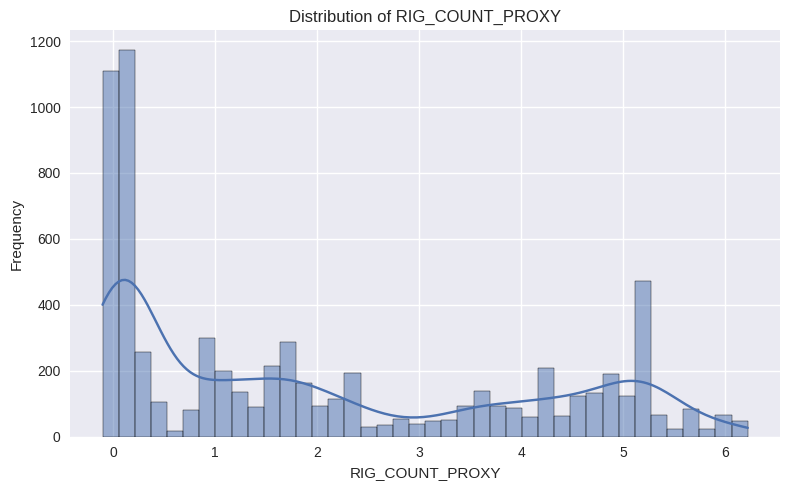

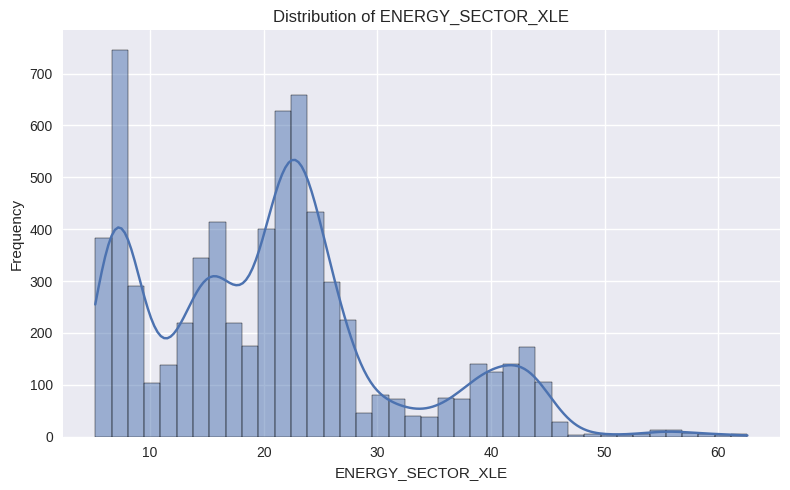

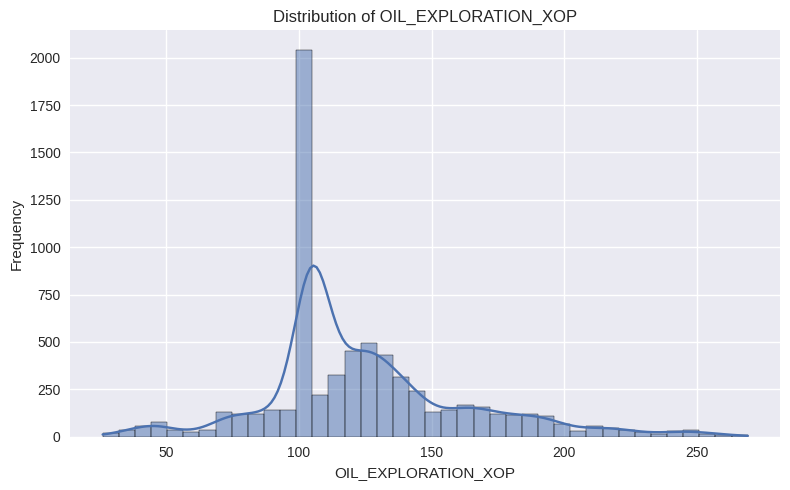

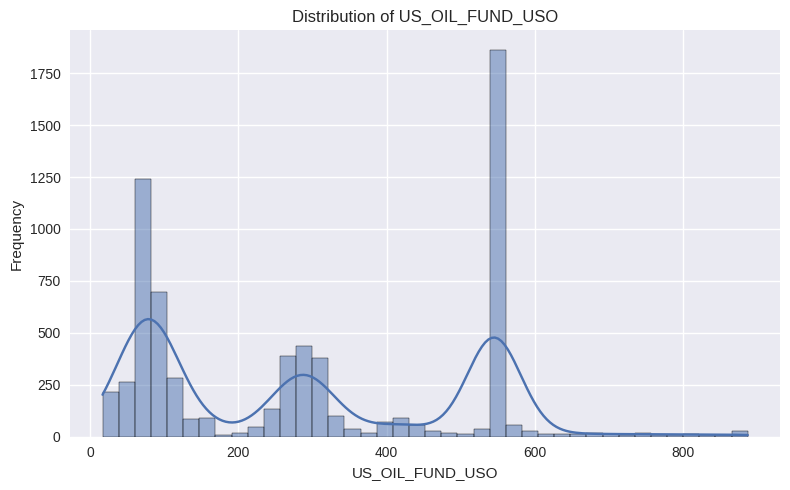

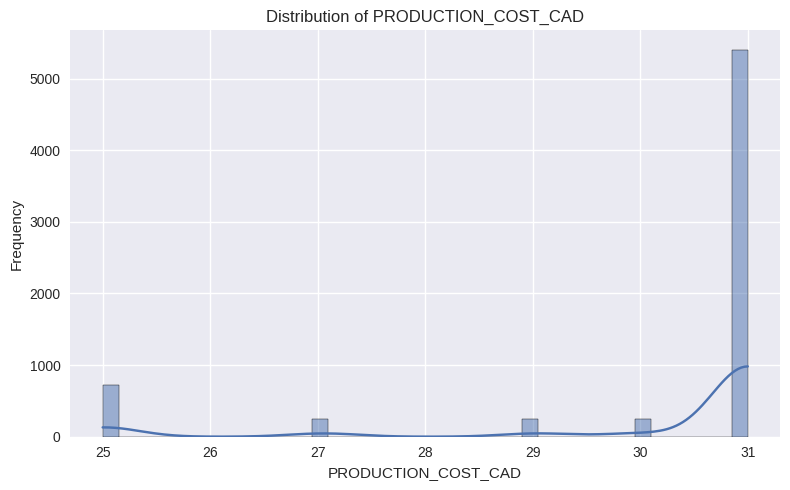

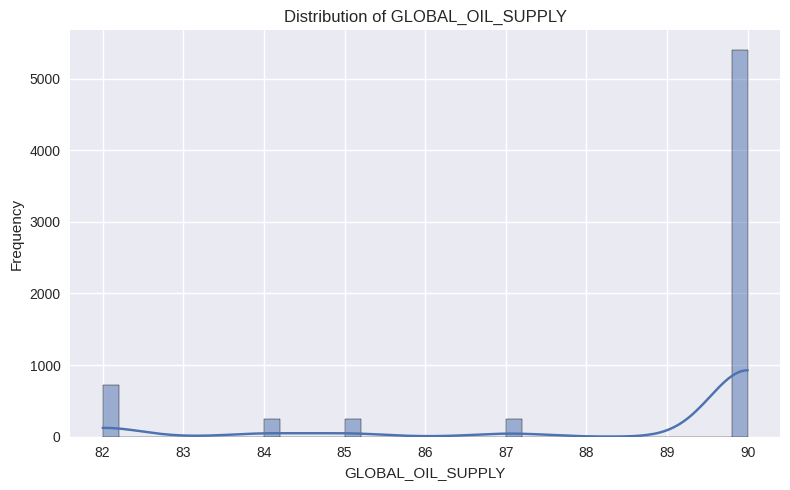

In [17]:
#Distribution Plot Student A

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")

# Select key variables for distribution analysis
dist_vars = [
    "OIL_PRICE_WTI", "SP500_INDEX", "USD_INDEX", "VIX",
    "GDP_US", "IND_PROD_US", "CPI_US",
    "RIG_COUNT_PROXY", "ENERGY_SECTOR_XLE", "OIL_EXPLORATION_XOP", "US_OIL_FUND_USO",
    "PRODUCTION_COST_CAD", "GLOBAL_OIL_SUPPLY"
]

for col in dist_vars:
    plt.figure(figsize=(8,5))
    sns.histplot(df[col], kde=True, bins=40)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


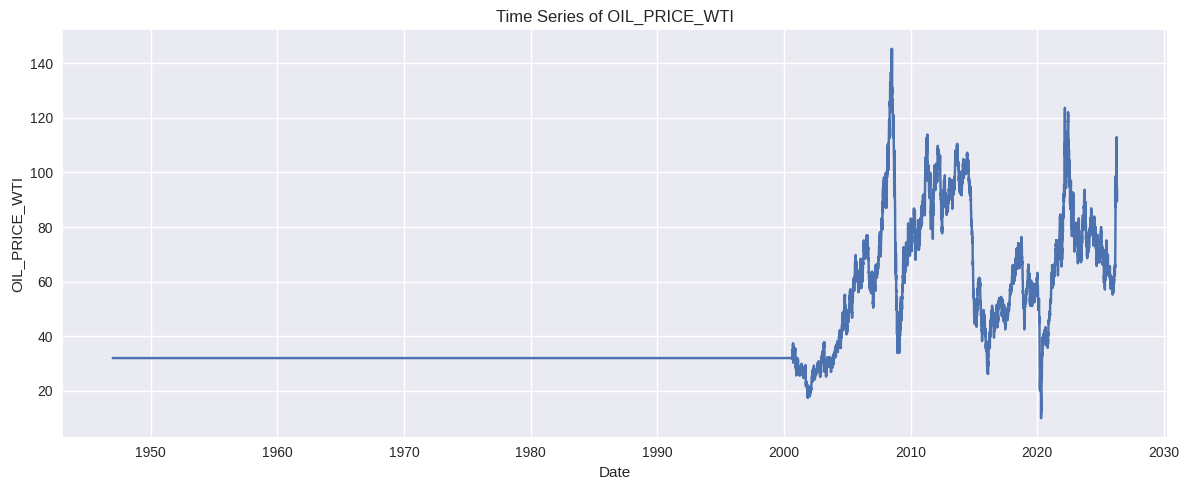

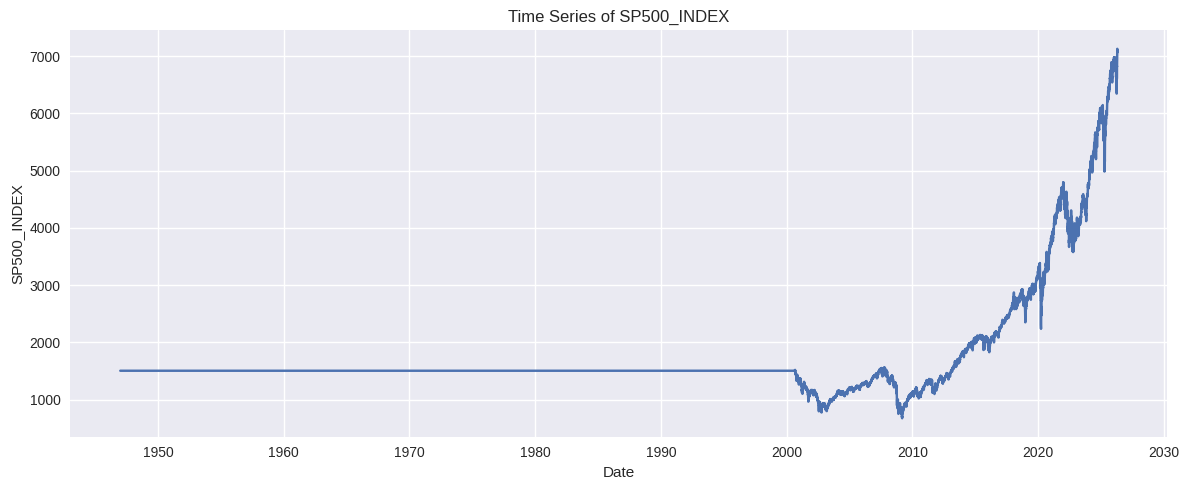

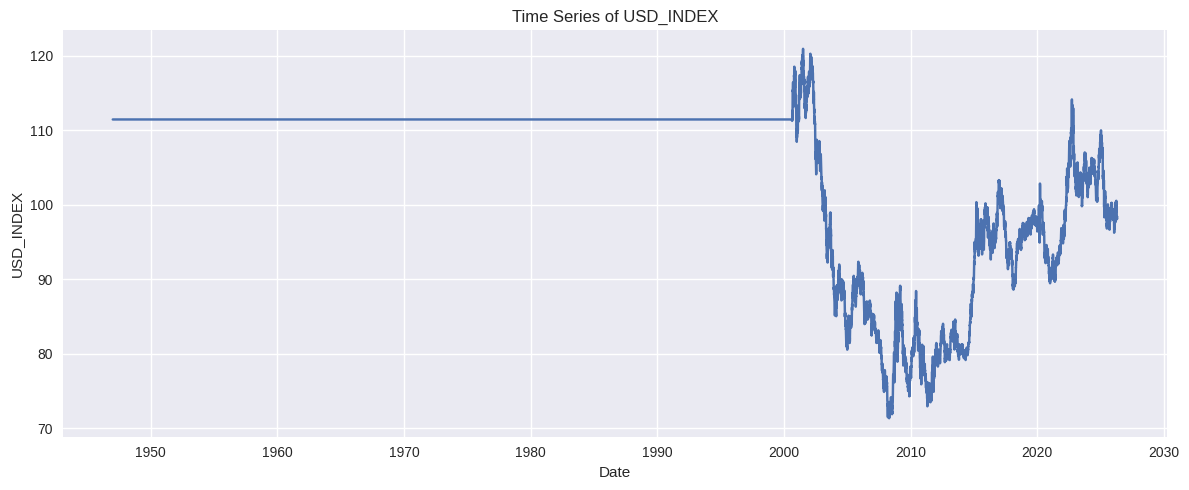

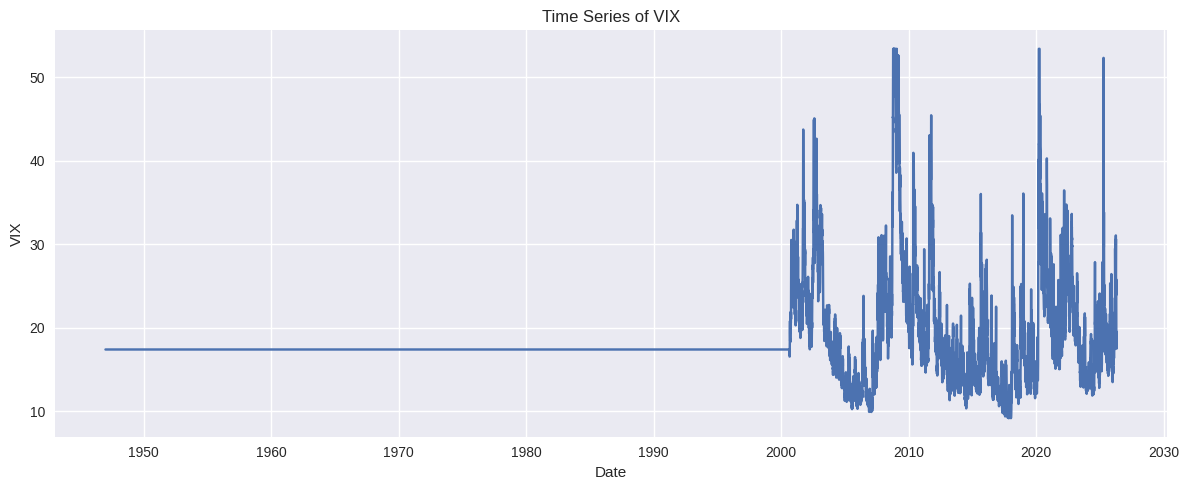

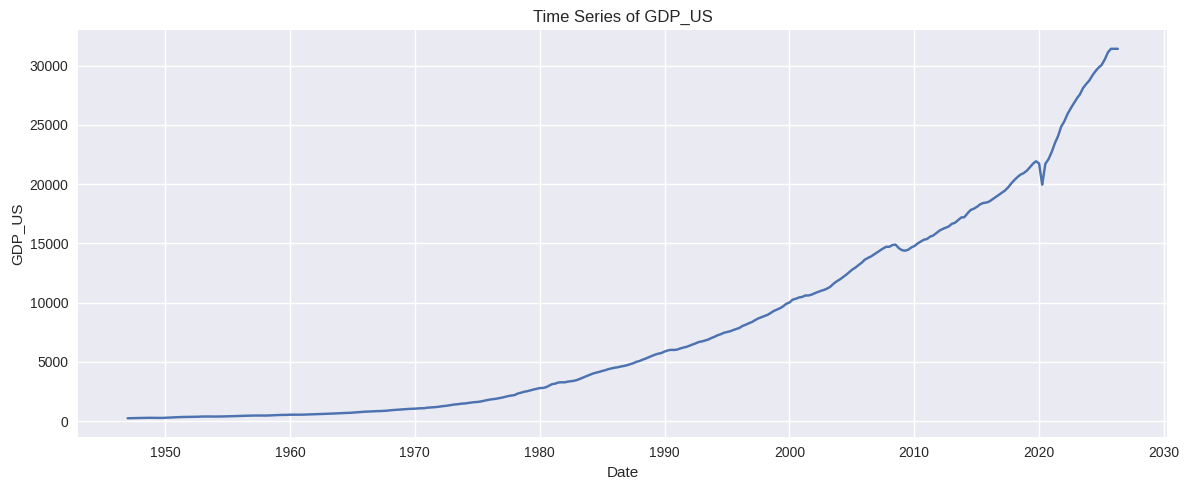

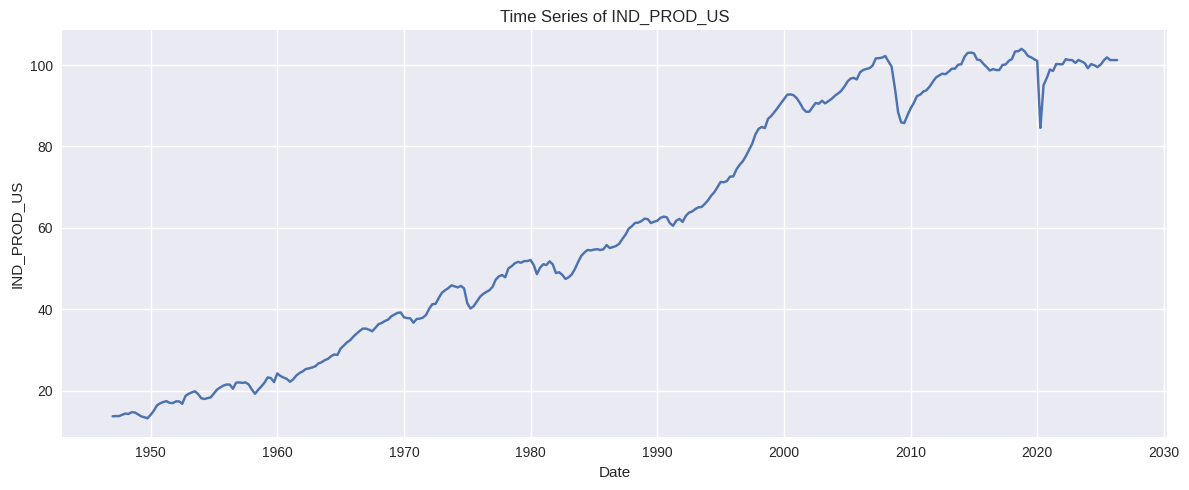

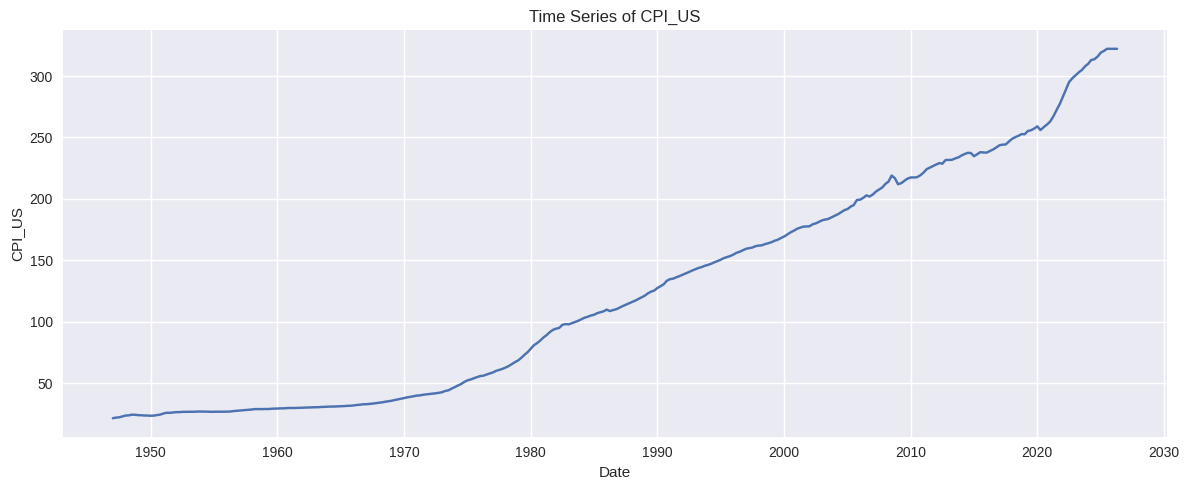

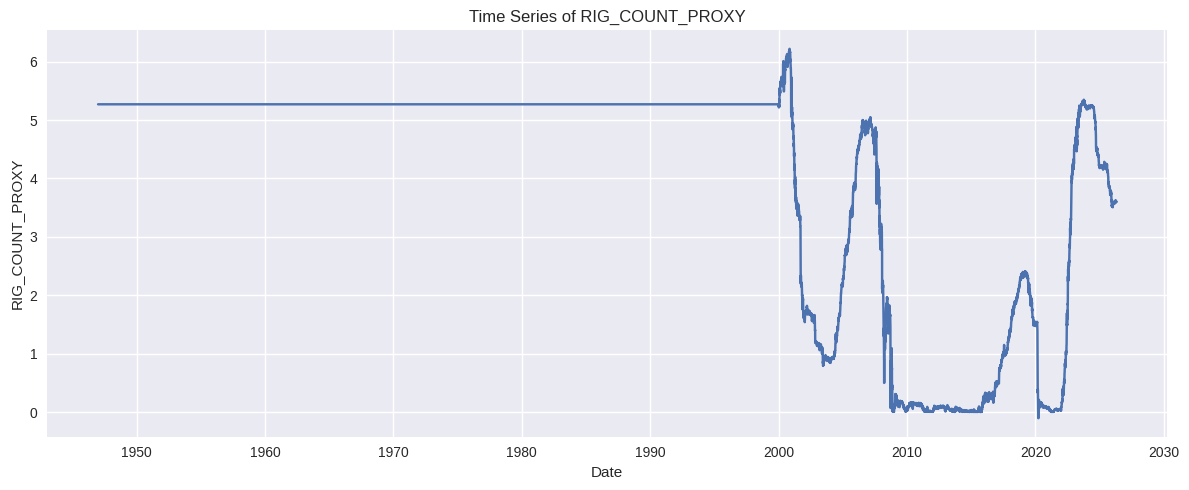

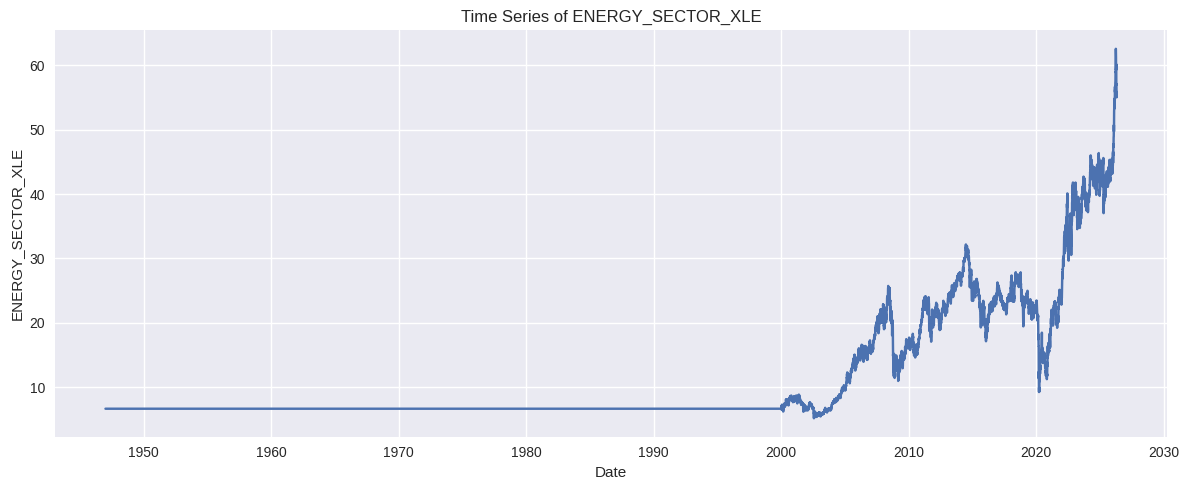

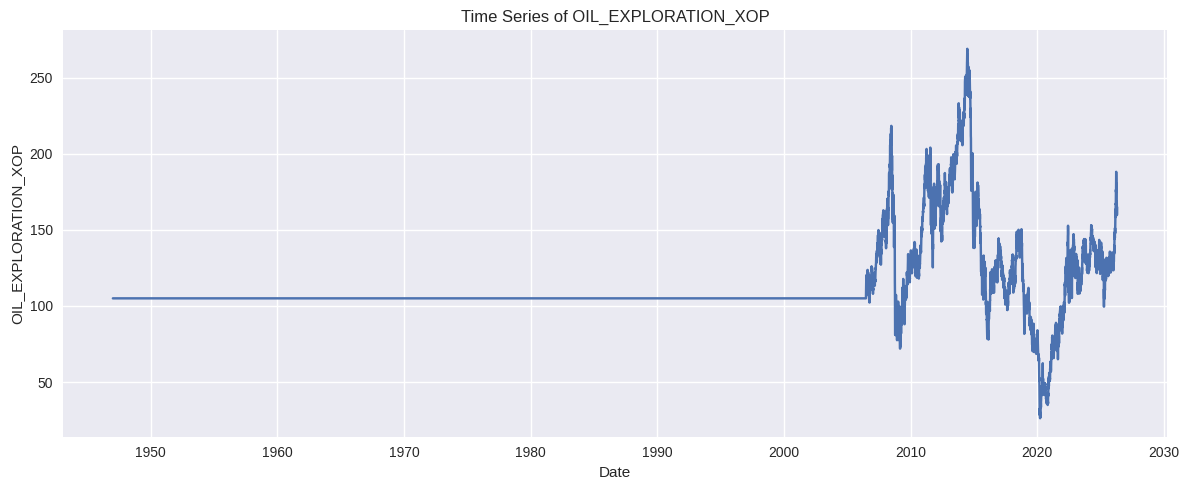

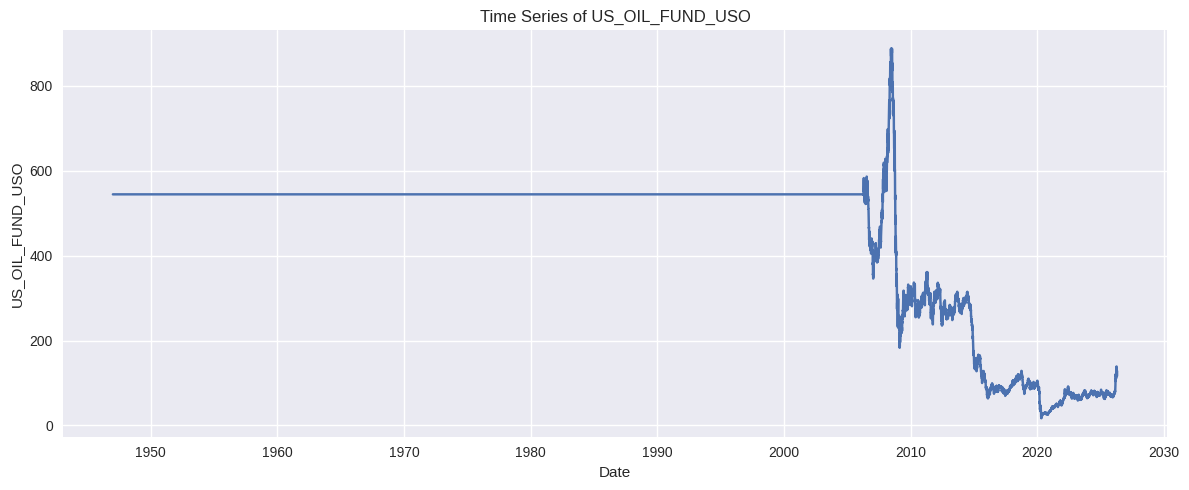

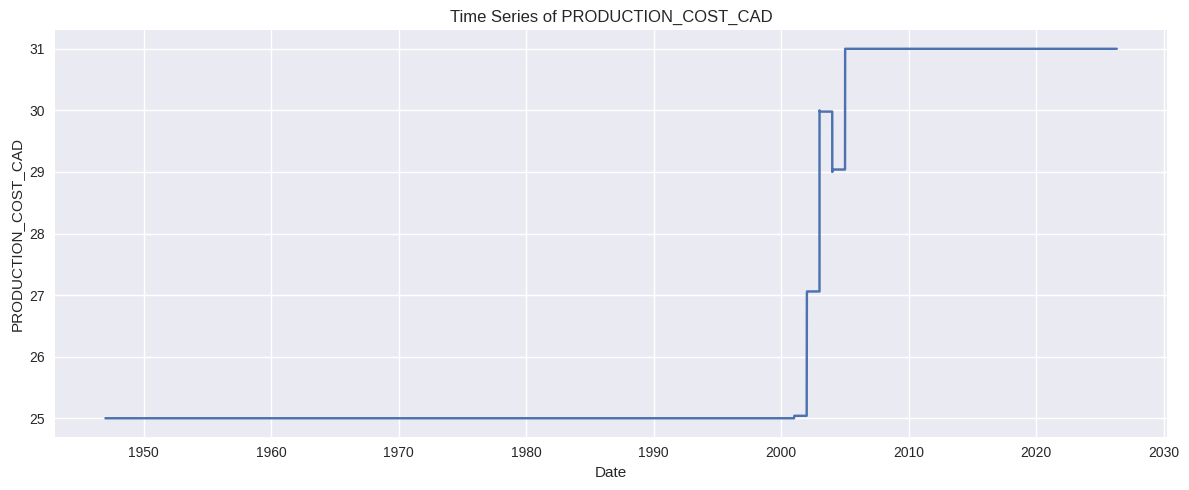

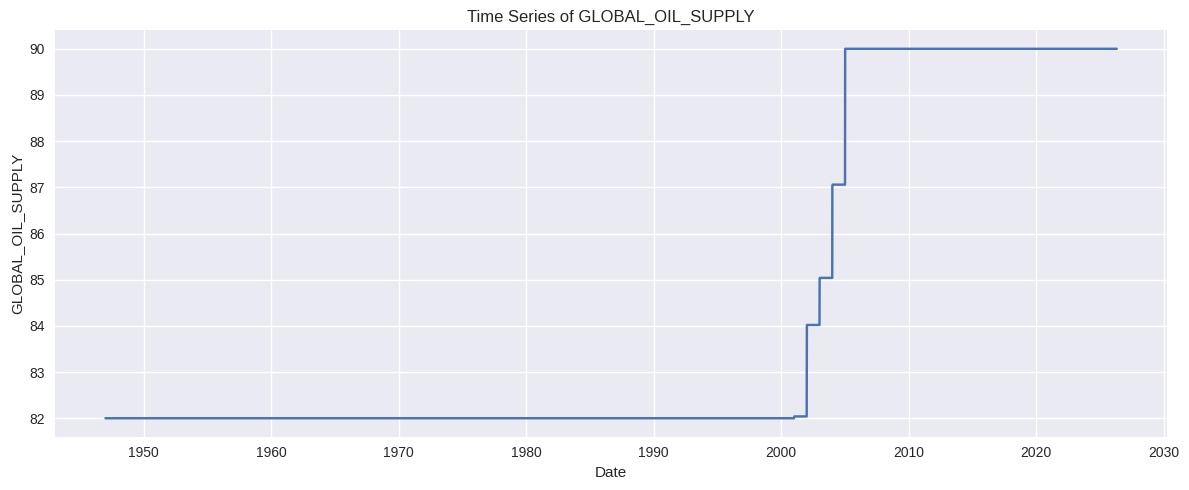

In [18]:
#Time-Series Plots Student B

ts_vars = [
    "OIL_PRICE_WTI", "SP500_INDEX", "USD_INDEX", "VIX",
    "GDP_US", "IND_PROD_US", "CPI_US",
    "RIG_COUNT_PROXY", "ENERGY_SECTOR_XLE", "OIL_EXPLORATION_XOP", "US_OIL_FUND_USO",
    "PRODUCTION_COST_CAD", "GLOBAL_OIL_SUPPLY"
]

for col in ts_vars:
    plt.figure(figsize=(12,5))
    plt.plot(df.index, df[col], label=col)
    plt.title(f"Time Series of {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


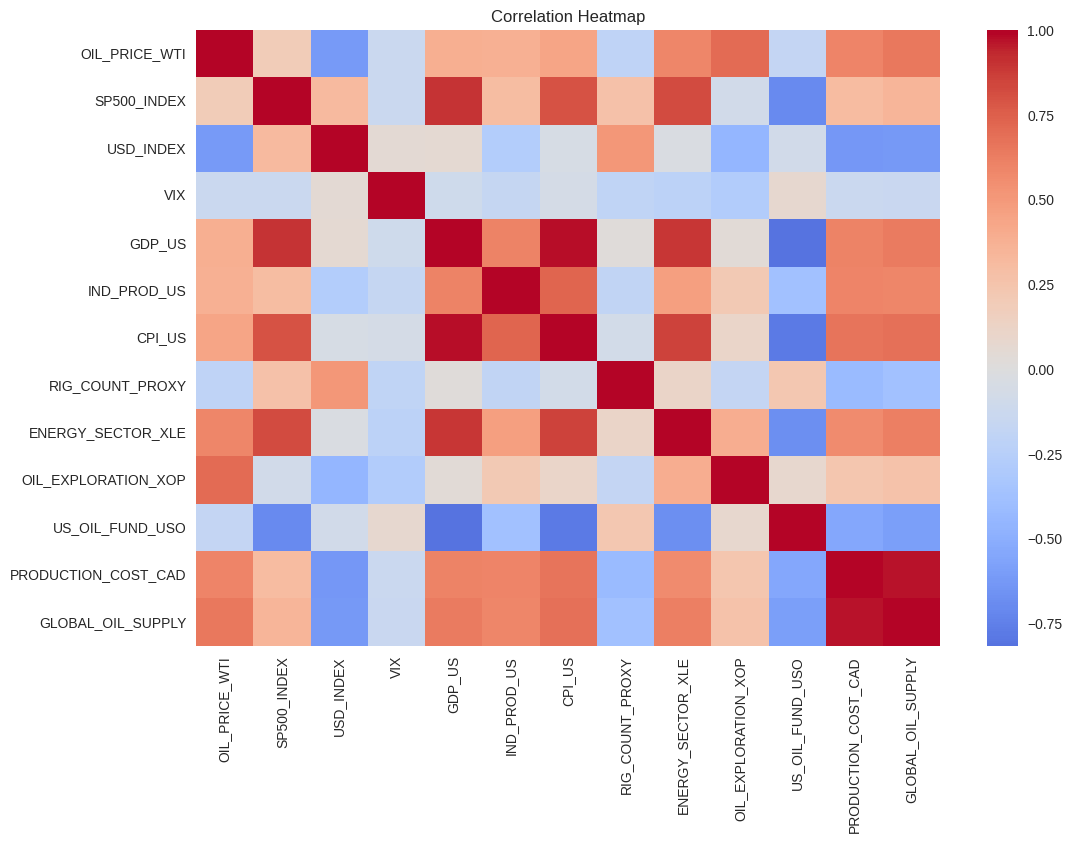

In [19]:
#3. Multivariate Plots (Student C)

#3a Correlation Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()


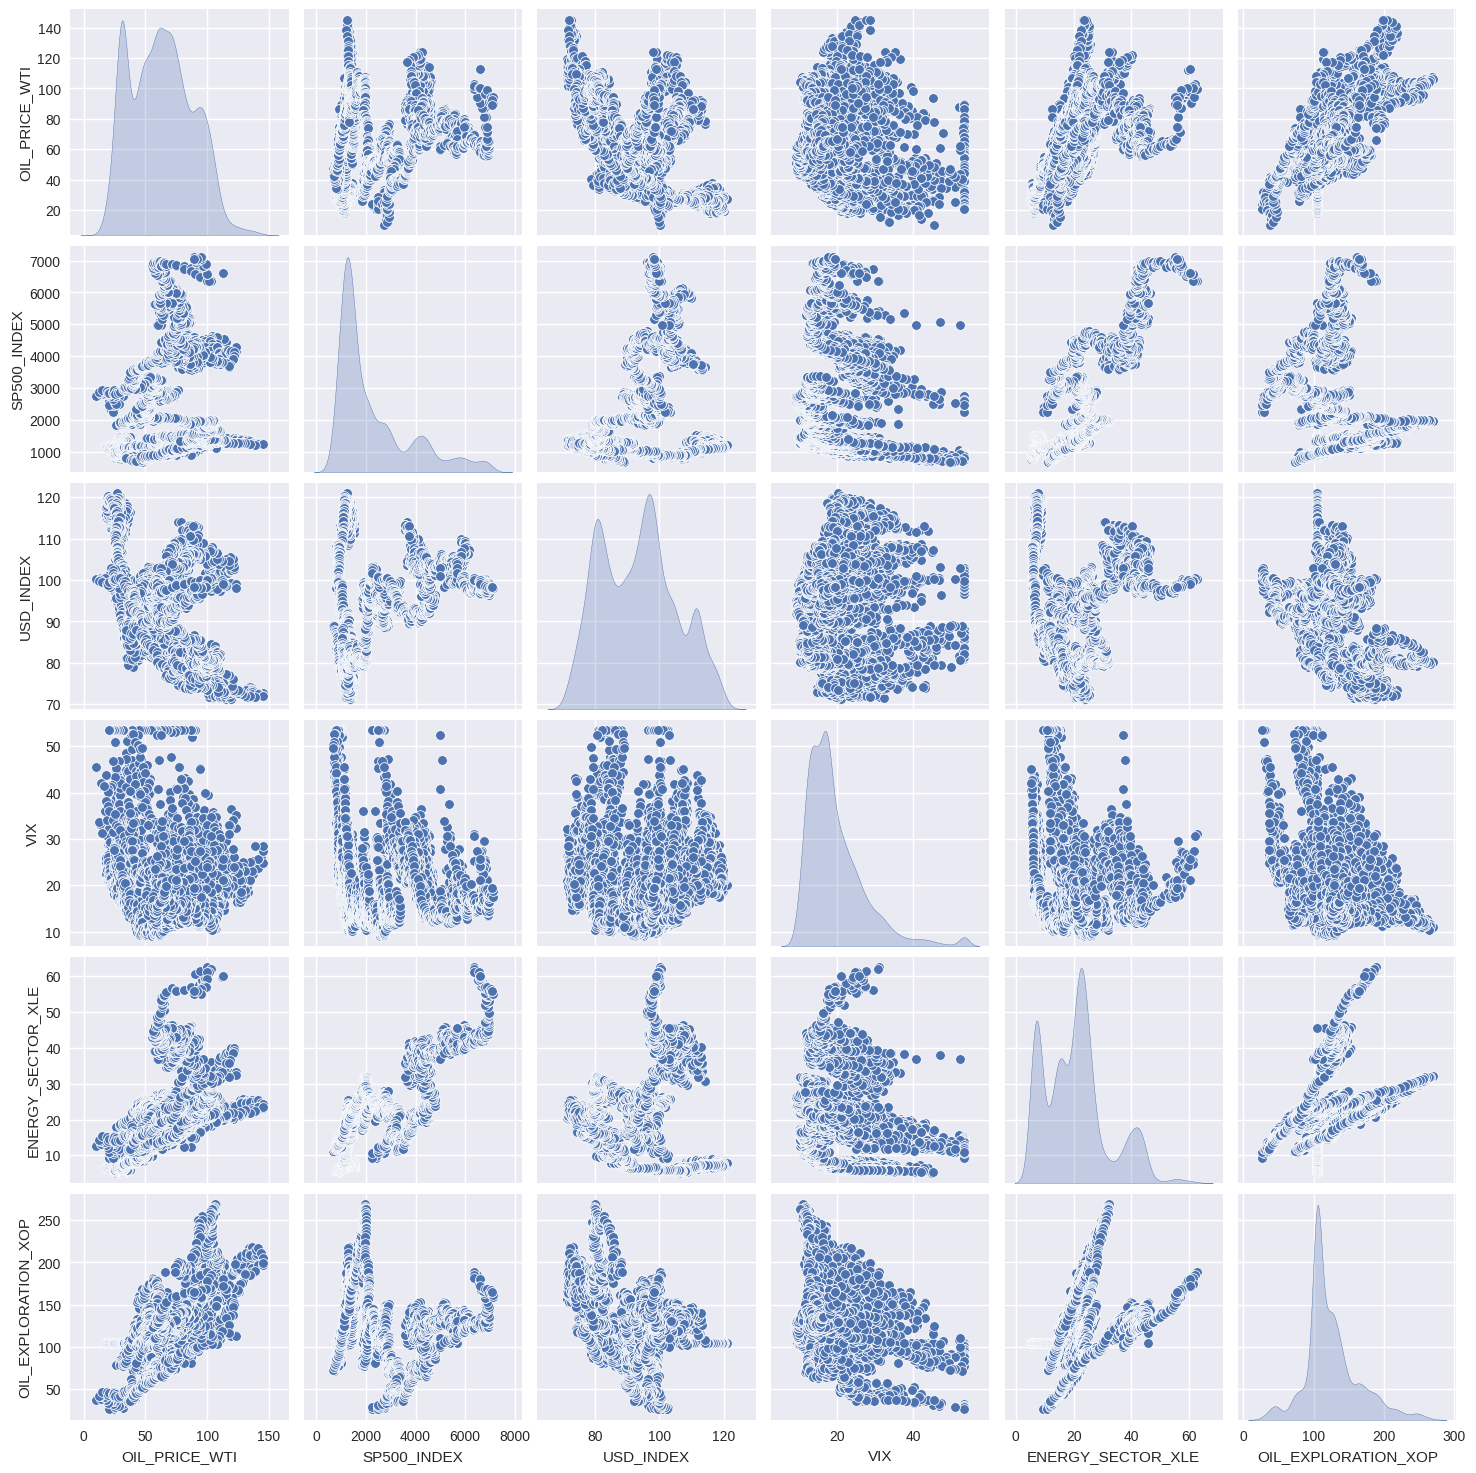

In [20]:
#3b Pairplot (Scatter matrix)

subset = df[[
    "OIL_PRICE_WTI", "SP500_INDEX", "USD_INDEX", "VIX",
    "ENERGY_SECTOR_XLE", "OIL_EXPLORATION_XOP"
]]

sns.pairplot(subset, diag_kind="kde")
plt.show()


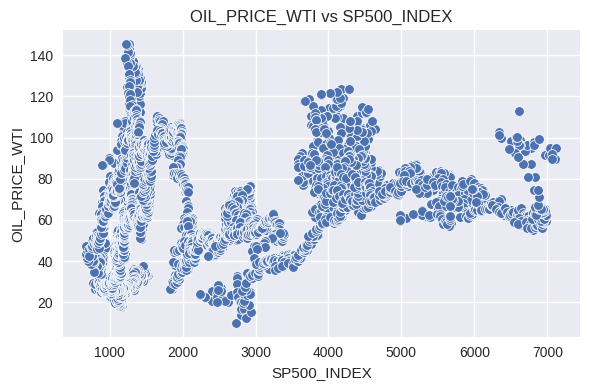

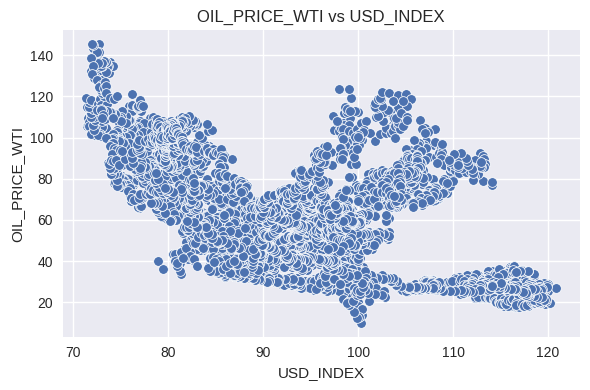

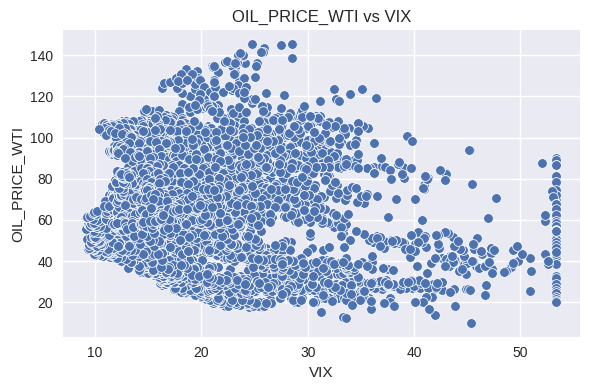

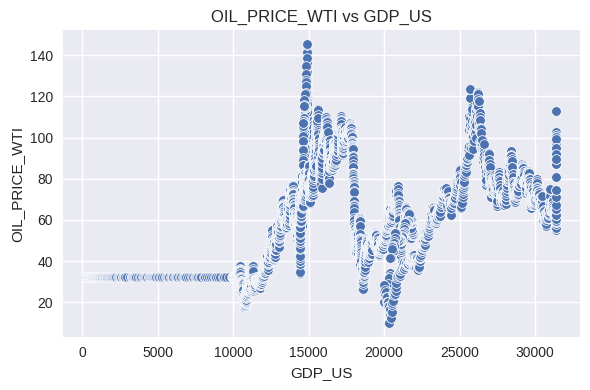

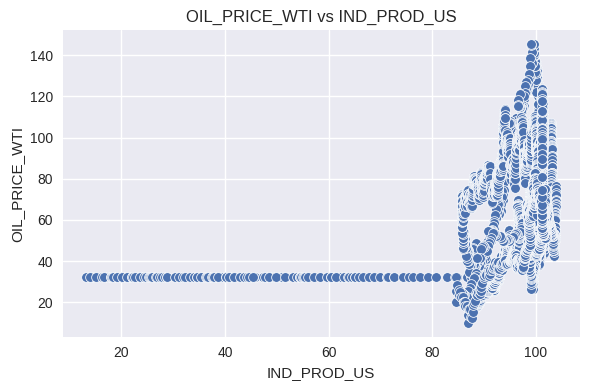

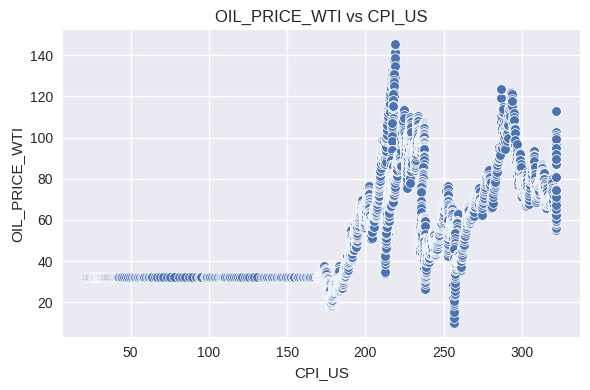

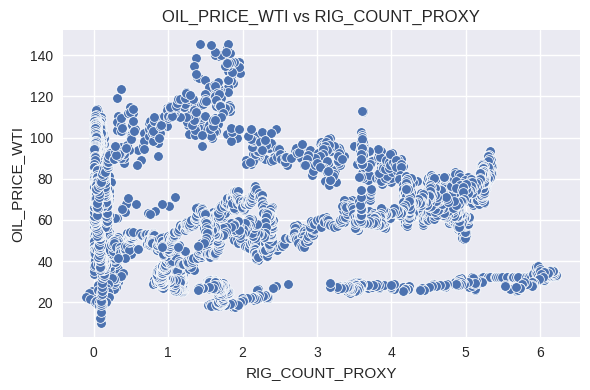

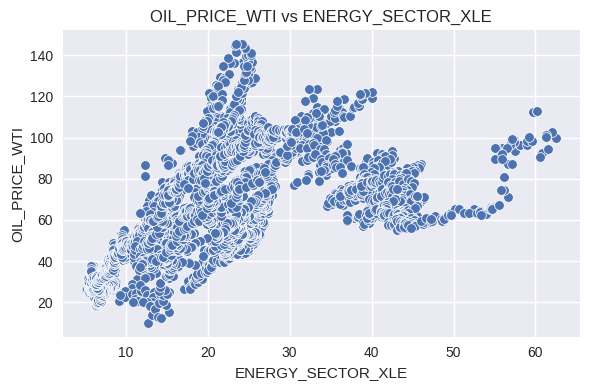

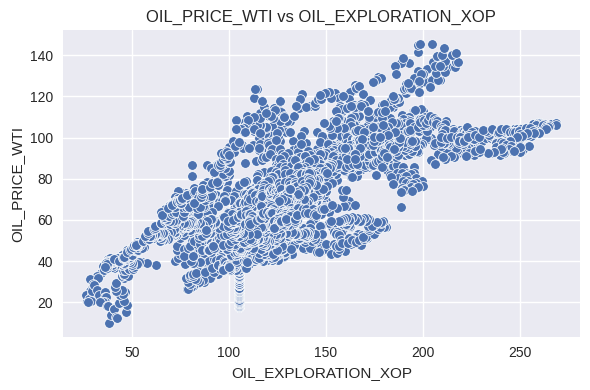

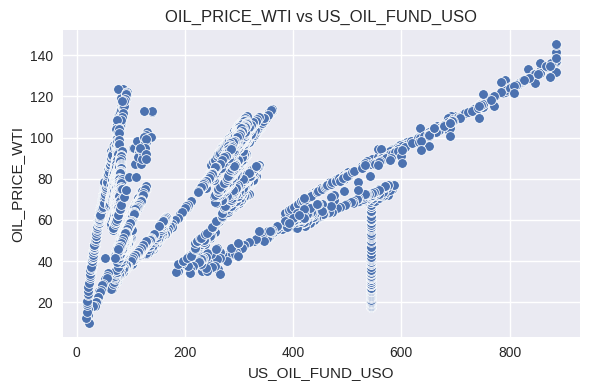

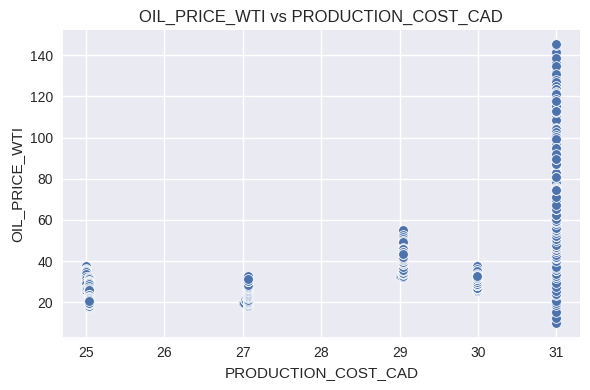

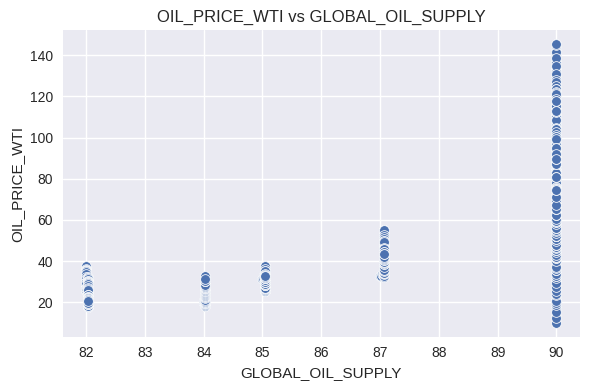

In [21]:
#3C. Scatter plots vs. oil price

target = "OIL_PRICE_WTI"

for col in df.columns:
    if col != target:
        plt.figure(figsize=(6,4))
        sns.scatterplot(x=df[col], y=df[target])
        plt.title(f"{target} vs {col}")
        plt.xlabel(col)
        plt.ylabel(target)
        plt.tight_layout()
        plt.show()


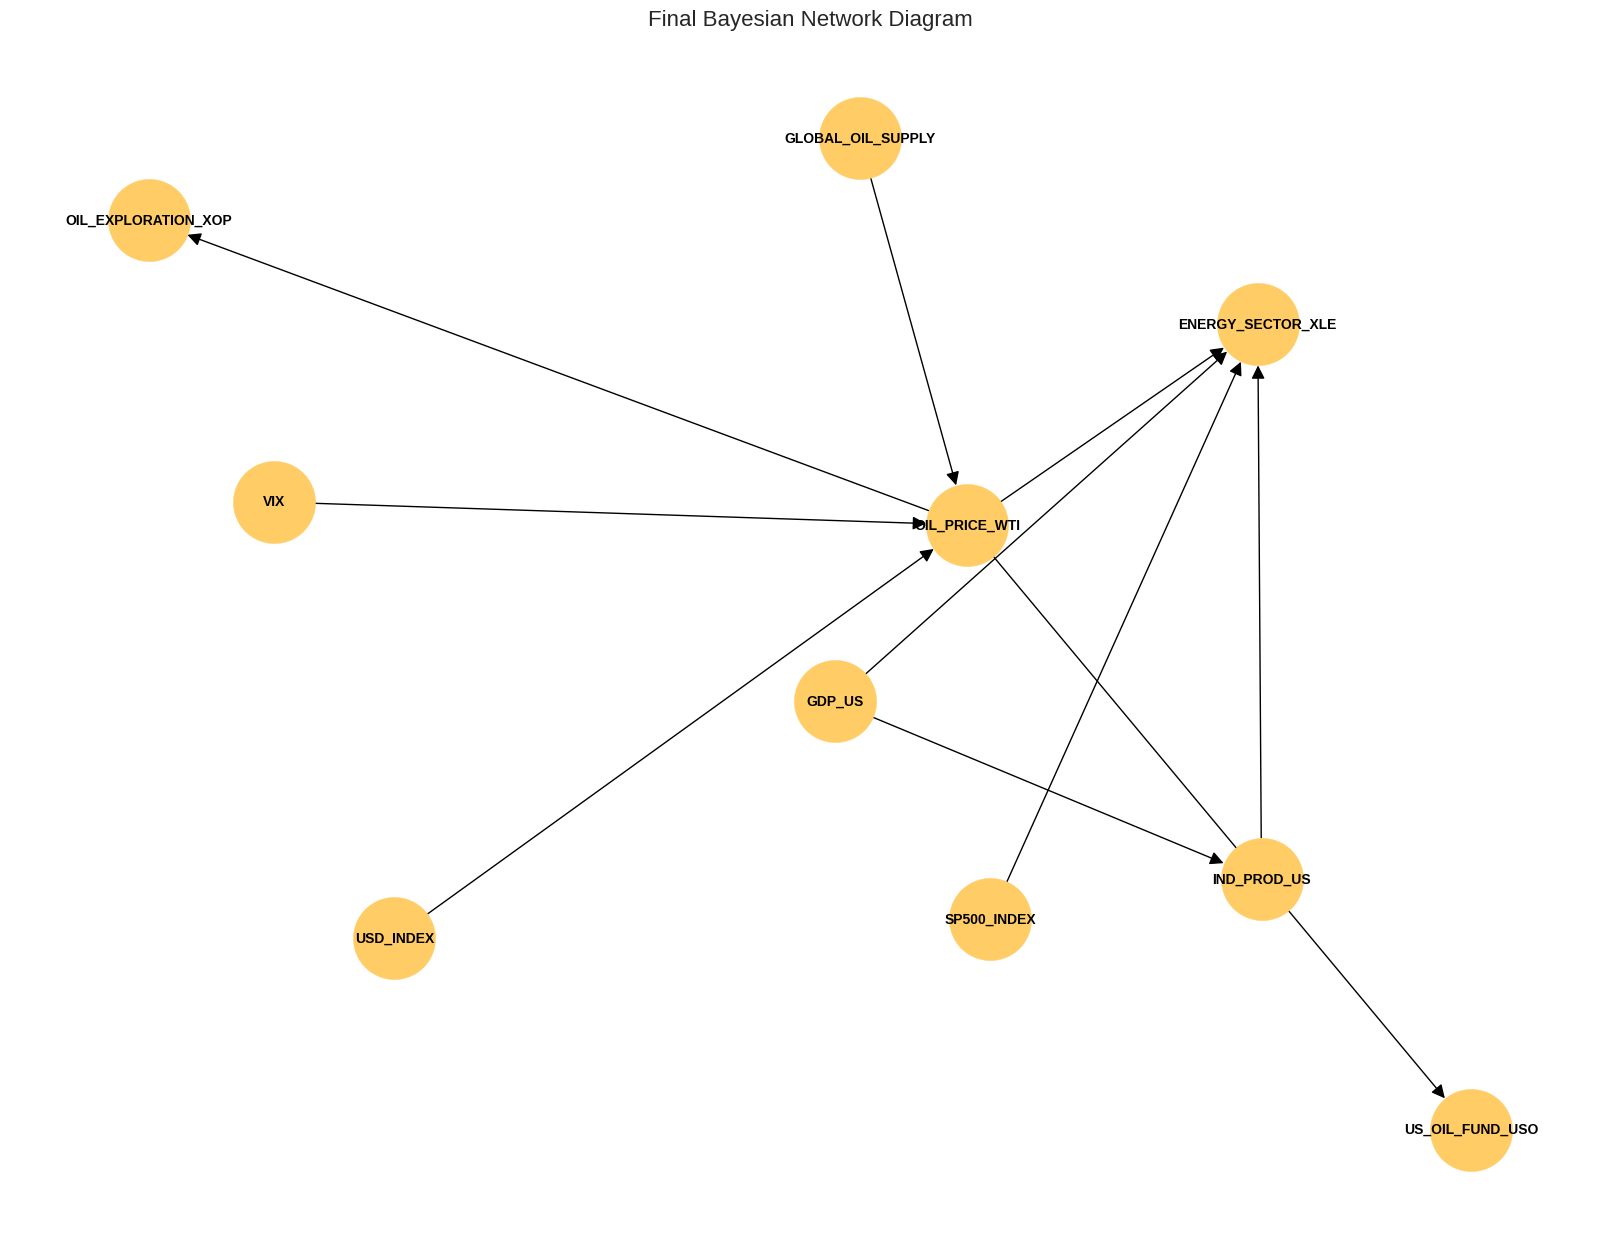

In [22]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a directed graph
G = nx.DiGraph()

# Add edges based on the final DAG structure
edges = [
    ("GLOBAL_OIL_SUPPLY", "OIL_PRICE_WTI"),
    ("USD_INDEX", "OIL_PRICE_WTI"),
    ("VIX", "OIL_PRICE_WTI"),

    ("OIL_PRICE_WTI", "ENERGY_SECTOR_XLE"),
    ("OIL_PRICE_WTI", "OIL_EXPLORATION_XOP"),
    ("OIL_PRICE_WTI", "US_OIL_FUND_USO"),

    ("SP500_INDEX", "ENERGY_SECTOR_XLE"),

    ("GDP_US", "IND_PROD_US"),
    ("IND_PROD_US", "ENERGY_SECTOR_XLE"),

    ("GDP_US", "ENERGY_SECTOR_XLE")
]

G.add_edges_from(edges)

# Layout for visualization
pos = nx.spring_layout(G, k=1.2, seed=42)

plt.figure(figsize=(16, 12))
nx.draw(
    G, pos,
    with_labels=True,
    node_size=3500,
    node_color="#ffcc66",
    font_size=10,
    font_weight="bold",
    arrowsize=20,
    arrowstyle="-|>"
)

plt.title("Final Bayesian Network Diagram", fontsize=16)
plt.show()
